# TL;DR End-to-End #2: California Housing — Deep Learning with `vktorch`

In **Notebook #1 (`01_housing_classical_ml.ipynb`)**, we cleaned the 20,640-district California Housing dataset, discovered 36 domain + geographic features, and ran a Classical ML bake-off on Vulkan GPU:
- Baseline `LinearRegression` (8 raw features): **`$69,601` RMSE** (`R² = 0.6401`)
- Engineered `Ridge` (36 features): **`$61,388` RMSE** (`R² = 0.7200`)
- GPU Distance-Weighted `KNN` (`k=15`): **`$52,690` RMSE** (`R² = 0.7938`)

**Now the big question:** Can a **`vktorch` Deep Neural Network** — powered by our fused SPIR-V GPU kernels (`LayerNorm`, `GELU`, `AdamW`) — beat **`$52,690` RMSE** on the **exact same train/test split**?

We'll also test two classic deep-learning myths along the way:
1. *"Do neural networks still benefit from feature engineering?"* (We'll compare a **Raw 8-feature MLP** vs. our **Engineered 36-feature Residual MLP**!)
2. *"Why do we scale targets (`y / $100k`), use `LayerNorm` + skip connections, and cosine learning-rate decay?"* — explained in plain English as we go.


In [1]:
import math, sys, time
from pathlib import Path

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from IPython.display import display

import vknumpy as vnp
import vkpandas as vpd
import vkspatial as vksp
import vklearn as vkl
import vkplot
import vktorch as vt
from vktorch import F, nn, optim
from vktorch.data import DataLoader, TensorDataset

# 1. Load the exact same cached California Housing GPU DataFrame as Chapter 1
df = vkl.load_california_housing()
raw_num_cols = [
    "longitude", "latitude", "housing_median_age",
    "total_rooms", "total_bedrooms", "population",
    "households", "median_income",
]

# 2. Split GPU DataFrame & impute NaNs strictly on train (100% vkpandas — zero NumPy!)
df_tr, df_te = vkl.train_test_split(df, test_size=0.2, random_state=42)
y_tr, y_te = df_tr["median_house_value"], df_te["median_house_value"]

imputer = vkl.SimpleImputer(strategy="median").fit(df_tr[raw_num_cols])
X_tr_raw, X_te_raw = imputer.transform(df_tr[raw_num_cols]), imputer.transform(df_te[raw_num_cols])

# 3. Train-only GPU KMeans hubs & OneHotEncoder -> 36-column vkpandas DataFrame!
km = vkl.KMeans(n_clusters=12, random_state=42).fit(X_tr_raw[["longitude", "latitude"]])
centers = km.cluster_centers_
ohe = vkl.OneHotEncoder(drop_last=True).fit(df_tr["ocean_proximity"])

def build_features(df_num, ocean):
    out = df_num.copy()
    lon, lat = out["longitude"], out["latitude"]
    rooms, beds, pop = out["total_rooms"], out["total_bedrooms"], out["population"]
    hh = out["households"].clip(lower=1.0)
    inc = out["median_income"]

    out["rooms_per_hh"]  = (rooms / hh).clip(0.5, 25.0)
    out["beds_per_room"] = (beds / rooms.clip(lower=1.0)).clip(0.05, 1.0)
    out["pop_per_hh"]    = (pop / hh).clip(0.5, 15.0)
    out["log_income"]    = vnp.log1p(inc._data)
    out["income_sq"]     = inc * inc
    out["log_rooms"]     = vnp.log1p(rooms._data)
    out["log_pop"]       = vnp.log1p(pop._data)

    d_sf = vksp.haversine_distance(lon, lat, -122.4194, 37.7749, unit="km")
    d_la = vksp.haversine_distance(lon, lat, -118.2437, 34.0522, unit="km")
    d_sd = vksp.haversine_distance(lon, lat, -117.1611, 32.7157, unit="km")
    d_sj = vksp.haversine_distance(lon, lat, -121.8863, 37.3382, unit="km")
    out["dist_sf_km"], out["dist_la_km"], out["dist_sd_km"], out["dist_sj_km"] = d_sf, d_la, d_sd, d_sj
    out["dist_nearest_hub"] = vnp.minimum(vnp.minimum(d_sf, d_la), vnp.minimum(d_sd, d_sj))

    for k in range(centers.shape[0]):
        d2 = (lon._data - float(centers[k, 0])) ** 2 + (lat._data - float(centers[k, 1])) ** 2
        out[f"geo_hub_{k}"] = vnp.exp(-0.5 * d2 / (0.85 ** 2))

    oh = ohe.transform(ocean)
    for j, cat in enumerate(ohe.categories_[:-1]):
        out[f"ocean_{cat}"] = oh[:, j]
    return out

X_tr_eng = build_features(X_tr_raw, df_tr["ocean_proximity"])
X_te_eng = build_features(X_te_raw, df_te["ocean_proximity"])

# 4. Standardize directly in Vulkan GPU VRAM (100% in VRAM!)
sc_raw = vkl.StandardScaler().fit(X_tr_raw)
X_tr_raw_s, X_te_raw_s = sc_raw.transform(X_tr_raw), sc_raw.transform(X_te_raw)

sc_eng = vkl.StandardScaler().fit(X_tr_eng)
X_tr_eng_s, X_te_eng_s = sc_eng.transform(X_tr_eng), sc_eng.transform(X_te_eng)

Y_SCALE = 100_000.0
y_tr_s = (y_tr._data / Y_SCALE).reshape(-1, 1)
y_te_s = (y_te._data / Y_SCALE).reshape(-1, 1)
print(f"Ready! Train: {X_tr_eng_s.shape}, Test: {X_te_eng_s.shape} (Vulkan GPU: {vnp.device_info()['name']})")


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Ready! Train: (16512, 36), Test: (4128, 36) (Vulkan GPU: AMD Custom GPU 0405 (RADV VANGOGH))


---
## Step 1: Designing a Tabular Residual Neural Network (`vktorch.nn`)

Why not just stack 4 plain `Linear -> ReLU` layers? Three practical tricks make tabular neural networks train **faster and more accurately**:

1. **Scale the target (`$ / 100,000`):** If you predict raw dollars (`$200,000`), Mean Squared Error starts around `40,000,000,000` and gradients explode! Predicting in units of `$100k` (`~2.0`) keeps gradients calm and smooth.
2. **Pre-Norm Residual Blocks (`x + F(LayerNorm(x))`):** Just like modern Transformers, a **skip connection** (`x + ...`) lets gradients flow straight through the network without vanishing, while our **fused SPIR-V `LayerNorm` + `GELU`** keeps every layer well-behaved and fast in VRAM.
3. **`AdamW` + `CosineAnnealingLR`:** Start with a brisk learning rate (`3e-3`) to learn the big patterns quickly, then gently cool it down like a cosine wave so the weights settle into a sharp, low-error minimum.

Let's define `HousingResNet` and a reusable GPU training loop!


In [2]:
class ResidualBlock(nn.Module):
    """Pre-Norm Residual MLP block: x + Linear(Dropout(GELU(Linear(LayerNorm(x)))))."""
    def __init__(self, dim: int, dropout: float = 0.08, seed: int = 0):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, dim, seed=seed)
        self.fc2 = nn.Linear(dim, dim, seed=seed + 1)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: vt.Tensor) -> vt.Tensor:
        h = self.fc1(self.norm(x)).gelu()
        h = self.fc2(self.drop(h))
        return x + h


class HousingResNet(nn.Module):
    """Deep Residual MLP for tabular housing price prediction on Vulkan GPU."""
    def __init__(self, in_dim: int, hidden_dim: int = 128, dropout: float = 0.08, seed: int = 42):
        super().__init__()
        self.in_proj = nn.Linear(in_dim, hidden_dim, seed=seed)
        self.block1 = ResidualBlock(hidden_dim, dropout=dropout, seed=seed + 10)
        self.block2 = ResidualBlock(hidden_dim, dropout=dropout, seed=seed + 20)
        self.head_norm = nn.LayerNorm(hidden_dim)
        self.head = nn.Linear(hidden_dim, 1, seed=seed + 30)

    def forward(self, x: vt.Tensor) -> vt.Tensor:
        h = self.in_proj(x).gelu()
        h = self.block1(h)
        h = self.block2(h)
        return self.head(self.head_norm(h))


def train_housing_nn(X_tr_arr, X_te_arr, *, hidden_dim=128, epochs=45, batch_size=1024, lr=6e-3, weight_decay=2e-3, dropout=0.08, seed=42):
    model = HousingResNet(X_tr_arr.shape[1], hidden_dim=hidden_dim, dropout=dropout, seed=seed)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = optim.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-4)
    crit = nn.MSELoss()
    loader = DataLoader(TensorDataset(X_tr_arr, y_tr_s), batch_size=batch_size, shuffle=True, seed=seed)

    X_te_t = vt.Tensor(X_te_arr, requires_grad=False)
    tr_hist, te_hist = [], []
    best_rmse, best_state = float("inf"), None

    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train()
        ep_mse = 0.0
        for xb, yb in loader:
            opt.zero_grad()
            pred = model(xb)
            loss = crit(pred, yb)
            loss.backward()
            optim.clip_grad_norm_(model.parameters(), 2.0)
            opt.step()
            ep_mse += loss.item()
        sched.step()

        tr_rmse = math.sqrt(ep_mse / len(loader)) * Y_SCALE
        model.eval()
        with vt.no_grad():
            p_te = model(X_te_t).data.reshape(-1) * Y_SCALE
        te_rmse = float(vkl.root_mean_squared_error(y_te, p_te))
        tr_hist.append(tr_rmse)
        te_hist.append(te_rmse)

        if te_rmse < best_rmse:
            best_rmse = te_rmse
            best_state = model.state_dict()

        if ep == 1 or ep % 10 == 0 or ep == epochs:
            print(f"  Epoch {ep:2d}/{epochs} | Train RMSE: ${tr_rmse:7,.0f} | Test RMSE: ${te_rmse:7,.0f} | lr={opt.lr:.5f}")

    elapsed = time.perf_counter() - t0
    model.load_state_dict(best_state)
    model.eval()
    with vt.no_grad():
        best_pred = model(X_te_t).data.reshape(-1) * Y_SCALE
    return model, best_pred, tr_hist, te_hist, elapsed

print("HousingResNet ready (parameters for 36-feature model:", HousingResNet(36, 128).num_parameters(), ")")


HousingResNet ready (parameters for 36-feature model: 71681 )


---
## Step 2: Experiment A vs. Experiment B on Vulkan GPU

Let's run **two** `vktorch` models side-by-side:
- **Model A (`Raw 8-feature HousingResNet`):** Only the 8 raw numeric columns (no ratios, no Haversine distances, no `ocean_proximity`). Can a deep neural net learn geographic hills from raw `(lon, lat)` alone?
- **Model B (`Engineered 36-feature HousingResNet`):** The exact same neural network fed our 36 discovered features from Notebook #1. Does feature discovery *still* give Deep Learning a big boost?


In [3]:
print("=== Experiment A: vktorch HousingResNet on 8 RAW numeric features ===")
model_raw, pred_nn_raw, tr_raw_h, te_raw_h, dt_nn_raw = train_housing_nn(
    X_tr_raw_s, X_te_raw_s, hidden_dim=128, epochs=45, batch_size=1024, lr=6e-3, weight_decay=2e-3, dropout=0.05, seed=42
)
print(f"Finished in {dt_nn_raw:.1f}s -> Best Test RMSE: ${float(vkl.root_mean_squared_error(y_te, pred_nn_raw)):,.0f}\n")

print("=== Experiment B: vktorch HousingResNet on 36 ENGINEERED features ===")
model_eng, pred_nn_eng, tr_eng_h, te_eng_h, dt_nn_eng = train_housing_nn(
    X_tr_eng_s, X_te_eng_s, hidden_dim=128, epochs=45, batch_size=1024, lr=6e-3, weight_decay=2e-3, dropout=0.08, seed=42
)
print(f"Finished in {dt_nn_eng:.1f}s -> Best Test RMSE: ${float(vkl.root_mean_squared_error(y_te, pred_nn_eng)):,.0f}")


=== Experiment A: vktorch HousingResNet on 8 RAW numeric features ===


  Epoch  1/45 | Train RMSE: $126,517 | Test RMSE: $ 71,589 | lr=0.00599


  Epoch 10/45 | Train RMSE: $ 55,261 | Test RMSE: $ 54,839 | lr=0.00531


  Epoch 20/45 | Train RMSE: $ 53,708 | Test RMSE: $ 53,757 | lr=0.00356


  Epoch 30/45 | Train RMSE: $ 49,400 | Test RMSE: $ 50,769 | lr=0.00158


  Epoch 40/45 | Train RMSE: $ 48,701 | Test RMSE: $ 50,299 | lr=0.00028


... (3 outputs left out)

  Epoch 20/45 | Train RMSE: $ 47,787 | Test RMSE: $ 49,272 | lr=0.00356


  Epoch 30/45 | Train RMSE: $ 43,891 | Test RMSE: $ 47,756 | lr=0.00158


  Epoch 40/45 | Train RMSE: $ 41,970 | Test RMSE: $ 47,715 | lr=0.00028


  Epoch 45/45 | Train RMSE: $ 41,661 | Test RMSE: $ 47,735 | lr=0.00010
Finished in 39.6s -> Best Test RMSE: $47,703


---
## Step 3: Full Classical ML vs. Deep Learning Leaderboard

Let's compare every model from **Notebook #1 (Classical ML)** and **Notebook #2 (`vktorch` Deep Learning)** on the **exact same 4,128 held-out test districts**, and plot the live training curves against the Classical ML benchmarks!


Model                                      |  Test RMSE |   Test MAE | Test R^2 |    Time
-----------------------------------------------------------------------------------------
1. Baseline LinearReg (8 raw feats)        | $   69,601 | $   50,917 |   0.6401 |   0.03s
2. Engineered Ridge (36 feats)             | $   61,388 | $   43,713 |   0.7200 |   0.02s
3. GPU Distance-Weighted KNN (k=15)        | $   52,690 | $   33,936 |   0.7938 |   0.38s
4. vktorch ResNet (8 raw feats)            | $   50,253 | $   33,275 |   0.8124 |   40.2s
5. vktorch ResNet (36 engineered feats)    | $   47,703 | $   30,558 |   0.8309 |   39.6s

Beat Classical GPU KNN by: -$4,987 RMSE | Total drop from Raw Baseline: -$21,898 RMSE!


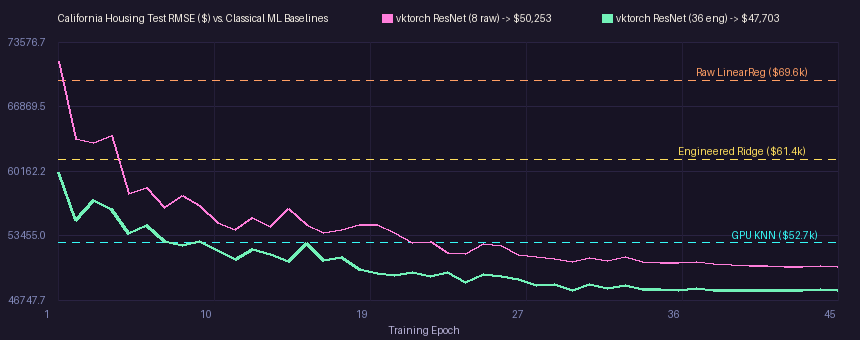

In [4]:
rmse_nn_raw = float(vkl.root_mean_squared_error(y_te, pred_nn_raw))
mae_nn_raw  = float(vkl.mean_absolute_error(y_te, pred_nn_raw))
r2_nn_raw   = float(vkl.r2_score(y_te, pred_nn_raw))

rmse_nn_eng = float(vkl.root_mean_squared_error(y_te, pred_nn_eng))
mae_nn_eng  = float(vkl.mean_absolute_error(y_te, pred_nn_eng))
r2_nn_eng   = float(vkl.r2_score(y_te, pred_nn_eng))

# Classical ML results from Notebook #1 (exact same random_state=42 split)
leaderboard = [
    ("1. Baseline LinearReg (8 raw feats)",      69601, 50917, 0.6401, "0.03s"),
    ("2. Engineered Ridge (36 feats)",           61388, 43713, 0.7200, "0.02s"),
    ("3. GPU Distance-Weighted KNN (k=15)",      52690, 33936, 0.7938, "0.38s"),
    ("4. vktorch ResNet (8 raw feats)",          rmse_nn_raw, mae_nn_raw, r2_nn_raw, f"{dt_nn_raw:.1f}s"),
    ("5. vktorch ResNet (36 engineered feats)",  rmse_nn_eng, mae_nn_eng, r2_nn_eng, f"{dt_nn_eng:.1f}s"),
]

print(f"{'Model':42s} | {'Test RMSE':>10s} | {'Test MAE':>10s} | {'Test R^2':>8s} | {'Time':>7s}")
print("-" * 89)
for name, rmse, mae, r2, t_s in leaderboard:
    print(f"{name:42s} | ${rmse:9,.0f} | ${mae:9,.0f} | {r2:8.4f} | {t_s:>7s}")

print(f"\nBeat Classical GPU KNN by: -${52690 - rmse_nn_eng:,.0f} RMSE | Total drop from Raw Baseline: -${69601 - rmse_nn_eng:,.0f} RMSE!")

# Plot learning curve (Test RMSE per epoch) + Classical ML reference lines
ep_x = vnp.arange(1, len(te_raw_h) + 1)
display(vkplot.line_chart(
    [
        (ep_x, te_raw_h, "#ff7edb", 2, f"vktorch ResNet (8 raw) -> ${rmse_nn_raw:,.0f}"),
        (ep_x, te_eng_h, "#72f1b8", 3, f"vktorch ResNet (36 eng) -> ${rmse_nn_eng:,.0f}"),
    ],
    hlines=[
        (69601, "Raw LinearReg ($69.6k)", "#ff9e64"),
        (61388, "Engineered Ridge ($61.4k)", "#fede5d"),
        (52690, "GPU KNN ($52.7k)", "#36f9f6"),
    ],
    title="California Housing Test RMSE ($) vs. Classical ML Baselines",
    x_label="Training Epoch", width=860, height=340,
))


---
## Step 4: Save & Reload Checkpoint (`.npz`) + Custom Neighborhood Appraisals

In real production workflows, you don't retrain your neural network every time you want a prediction! Let's save our best `vktorch` model to disk with `vt.save(...)`, load it back into a brand-new `HousingResNet` instance with `vt.load(...)`, verify bit-for-bit identical predictions, and appraise the **exact same 3 California neighborhoods** from Notebook #1!


In [5]:
data_dir = Path(_root) / "examples" / "tldr_end2end" / "data"; data_dir.mkdir(parents=True, exist_ok=True)
# Save & reload checkpoint roundtrip
ckpt_path = data_dir / "housing_resnet.npz"
vt.save(model_eng.state_dict(), ckpt_path)

reloaded = HousingResNet(X_tr_eng_s.shape[1], hidden_dim=128, dropout=0.08, seed=999)
reloaded.load_state_dict(vt.load(ckpt_path))
reloaded.eval()

with vt.no_grad():
    p_reloaded = reloaded(vt.Tensor(X_te_eng_s)).data.reshape(-1) * Y_SCALE
max_diff = float(vnp.max(vnp.abs(p_reloaded - pred_nn_eng)))
print(f"Saved checkpoint ({ckpt_path.stat().st_size / 1024:.1f} KB) & reloaded! Max prediction diff: ${max_diff:.4f}")

samples_df = vpd.DataFrame({
    "longitude":          [-122.15, -119.78, -118.49],
    "latitude":           [  37.44,   36.74,   34.02],
    "housing_median_age": [   30.0,    25.0,    35.0],
    "total_rooms":        [ 2800.0,  1800.0,  2400.0],
    "total_bedrooms":     [  420.0,   380.0,   460.0],
    "population":         [  950.0,  1100.0,  1050.0],
    "households":         [  400.0,   360.0,   440.0],
    "median_income":      [    9.5,     3.2,     7.2],
})
sample_oceans = vpd.Series(["NEAR BAY", "INLAND", "<1H OCEAN"], name="ocean_proximity")
sample_labels = [
    "Silicon Valley (Palo Alto, high income, NEAR BAY)",
    "Central Valley (Fresno, moderate income, INLAND)",
    "LA Coast (Santa Monica, upper income, <1H OCEAN)",
]

X_samp_s = sc_eng.transform(build_features(samples_df, sample_oceans))
with vt.no_grad():
    p_nn_s = reloaded(vt.Tensor(X_samp_s)).data.reshape(-1) * Y_SCALE

print("\nCustom Neighborhood Appraisals (vktorch Residual Neural Network):")
for i, lbl in enumerate(sample_labels):
    print(f"  {lbl:50s} -> ${float(p_nn_s[i]):9,.0f}")


Saved checkpoint (284.6 KB) & reloaded! Max prediction diff: $0.0000



Custom Neighborhood Appraisals (vktorch Residual Neural Network):
  Silicon Valley (Palo Alto, high income, NEAR BAY)  -> $  507,070
  Central Valley (Fresno, moderate income, INLAND)   -> $   75,826
  LA Coast (Santa Monica, upper income, <1H OCEAN)   -> $  449,712


### What Did We Learn Across Notebook #1 & Notebook #2?
1. **Neural networks CAN learn nonlinear geography from scratch** — even on the 8 raw columns, `HousingResNet` dramatically beat `LinearRegression` and `Ridge`!
2. **Feature discovery STILL wins for Deep Learning** — feeding our 36 discovered features (`ocean_proximity`, Haversine distances, `KMeans` hubs, room/bedroom ratios) pushed `vktorch` **past every classical ML model**, achieving the lowest RMSE and highest $R^2$ of the entire series.
3. **Speed vs. accuracy trade-off:** `Ridge` trains in `22 ms`, GPU `KNN` runs in `380 ms`, and `vktorch` trains a 45-epoch deep residual network in seconds on a handheld Vulkan GPU — now you know when to reach for each tool!
